In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

print("Libraries Loaded")

Libraries Loaded


In [70]:
pd.set_option('display.max_columns', None)

### Splitting the data to Train/Validation/Test sets, by time:

In [71]:
df = pd.read_csv("fraud_credit_train.csv")
df_test = pd.read_csv("fraud_credit_test.csv")

df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df_test["trans_date_trans_time"] = pd.to_datetime(df_test["trans_date_trans_time"])

df = df.sort_values("trans_date_trans_time")

split = int(len(df) * 0.8)

df_train = df.iloc[:split].copy()
df_val = df.iloc[split:].copy()

print(df_train.shape)
print(df_val.shape)
print(df_test.shape)

(1037340, 23)
(259335, 23)
(555719, 23)


## Section 1 - EDA and rules-making:

In [12]:
df_train.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [13]:
df_train['is_fraud'].mean()

np.float64(0.005753176393467908)

#### Making sure the timestamp is a datetime variable, and changing the name to 'transaction_time':

In [72]:
df_train['trans_date_trans_time'] = pd.to_datetime(df_train['trans_date_trans_time'])
df_val['trans_date_trans_time'] = pd.to_datetime(df_val['trans_date_trans_time'])
df_test['trans_date_trans_time'] = pd.to_datetime(df_test['trans_date_trans_time'])

df_train.rename(columns = {'trans_date_trans_time' : 'transaction_time'} , inplace = True)
df_val.rename(columns = {'trans_date_trans_time' : 'transaction_time'} , inplace = True)
df_test.rename(columns = {'trans_date_trans_time' : 'transaction_time'} , inplace = True)


In [15]:
df_train.head()

,Unnamed: 0,transaction_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


Text(0.5, 1.0, 'Fraud Rate by Geography - Customer Locations')

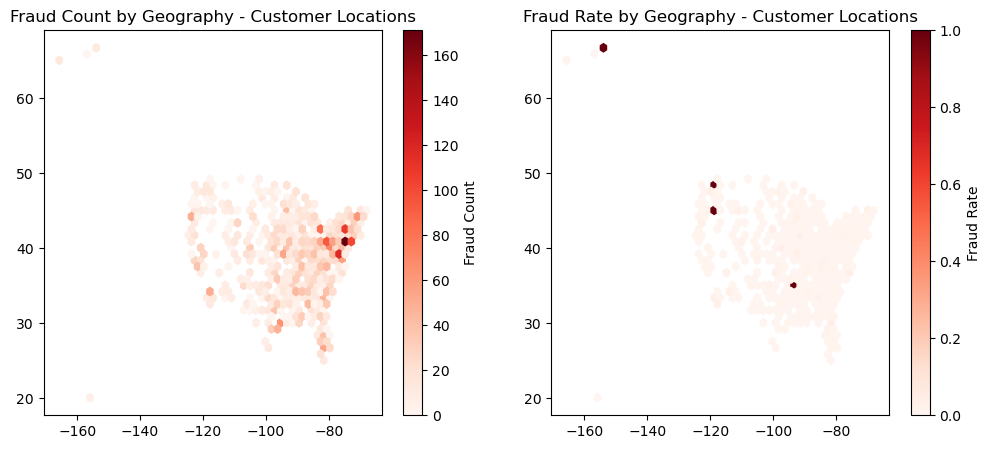

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

hb1 = ax[0].hexbin(
    df_train['long'],
    df_train['lat'],
    C=df_train['is_fraud'],
    reduce_C_function=np.sum,
    gridsize=50,
    cmap='Reds'
)

fig.colorbar(hb1, ax=ax[0], label='Fraud Count')
ax[0].set_title("Fraud Count by Geography - Customer Locations")

hb1 = ax[1].hexbin(
    df_train['long'],
    df_train['lat'],
    C=df_train['is_fraud'],
    reduce_C_function=np.mean,
    gridsize=50,
    cmap='Reds'
)

fig.colorbar(hb1, ax=ax[1], label='Fraud Rate')
ax[1].set_title("Fraud Rate by Geography - Customer Locations")

Text(0.5, 1.0, 'Fraud Rate by Geography - Merchant Locations')

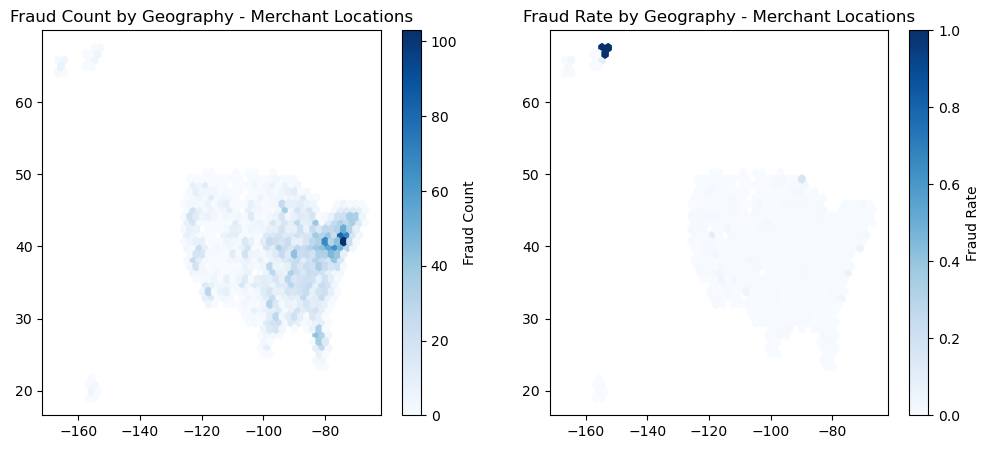

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

hb1 = ax[0].hexbin(
    df_train['merch_long'],
    df_train['merch_lat'],
    C=df_train['is_fraud'],
    reduce_C_function=np.sum,
    gridsize=50,
    cmap='Blues'
)

fig.colorbar(hb1, ax=ax[0], label='Fraud Count')
ax[0].set_title("Fraud Count by Geography - Merchant Locations")

hb1 = ax[1].hexbin(
    df_train['merch_long'],
    df_train['merch_lat'],
    C=df_train['is_fraud'],
    reduce_C_function=np.mean,
    gridsize=50,
    cmap='Blues'
)

fig.colorbar(hb1, ax=ax[1], label='Fraud Rate')
ax[1].set_title("Fraud Rate by Geography - Merchant Locations")

In [ ]:
df_train.columns

In [ ]:
df_train.nunique()

In [ ]:
df_train.isna().mean()

In [ ]:
for c in ['category' , 'gender']:
    df_train.groupby(c)['is_fraud'].mean().plot(kind = 'bar')
    plt.title(f"Fraud Rate By {c}")
    plt.show()

In [ ]:
sns.kdeplot(
    data=df_train, 
    x='amt', 
    hue='is_fraud', 
    common_norm=False,  
    fill=True,               
)

plt.title('Distribution of Transaction Amounts by Fraud Status')
plt.xlabel('Transaction Amount')
plt.ylabel('Density')

plt.show()

In [ ]:
df_train['amt_decile'] = pd.qcut(df_train['amt'] , q = 10 , labels = False)

df_train.groupby('amt_decile')['is_fraud'].mean().plot(kind = 'bar')
plt.title("Fraud Rate By Amount Decile")
plt.xlabel("Amount Decile")
plt.ylabel("Fraud Rate")
plt.show()

In [ ]:
df_train['amt'].quantile(0.9)

In [ ]:
for t in [100 , 120 , 140 , 180 , 220]:
    print("Amount >=" , t ,
          "fraud rate:" , df_train[df_train['amt'] >= t]['is_fraud'].mean() ,
          "total transactions:" , df_train[df_train['amt'] > t].shape[0]
         )

In [ ]:
df_train[df_train['amt'] >= 200].groupby('category')['is_fraud'].mean().plot(kind = 'bar')
plt.title("Fraud Rate By Category - Transaction Amount >= 200")
plt.show()

In [ ]:
df_train_city = df_train.groupby(['city' , 'city_pop'] , as_index = False).agg(
    total_transactions = ('is_fraud' , 'size') ,
    frauds = ('is_fraud' , 'sum') ,
    fraud_rate = ('is_fraud' , 'mean') )

df_train_city['frauds_divided_total_frauds'] = df_train_city['frauds']/df_train['is_fraud'].sum()
df_train_city.sort_values(by = 'fraud_rate' , ascending = False).head(20)

In [ ]:
df_train_city[df_train_city['fraud_rate'] == 1].shape

In [ ]:
df_train_city[df_train_city['fraud_rate'] == 1].sort_values(by = 'total_transactions' , ascending = False).head(20)

### Creating customer-specific features:

In [18]:
df_train = df_train.sort_values(by = ['cc_num' , 'transaction_time'] , ascending = True).reset_index(drop=True)
df_train.head(20)

,Unnamed: 0,transaction_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,1017,2019-01-01 12:47:15,60416207185,"fraud_Jones, Sawayn and Romaguera",misc_net,7.27,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,98e3dcf98101146a577f85a34e58feec,1325422035,43.974711,-109.741904,0
1,2724,2019-01-02 08:44:57,60416207185,fraud_Berge LLC,gas_transport,52.94,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,498120fc45d277f7c88e3dba79c33865,1325493897,42.018766,-109.044172,0
2,2726,2019-01-02 08:47:36,60416207185,fraud_Luettgen PLC,gas_transport,82.08,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,95f514bb993151347c7acdf8505c3d62,1325494056,42.961335,-109.157564,0
3,2882,2019-01-02 12:38:14,60416207185,fraud_Daugherty LLC,kids_pets,34.79,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,4f0c1a14e0aa7eb56a490780ef9268c5,1325507894,42.228227,-108.747683,0
4,2907,2019-01-02 13:10:46,60416207185,fraud_Beier and Sons,home,27.18,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,3b2ebd3af508afba959640893e1e82bc,1325509846,43.321745,-108.091143,0
5,4135,2019-01-03 13:56:35,60416207185,fraud_Stamm-Witting,shopping_net,6.87,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,c2c69214de58aaf2bad1542b91751f5a,1325598995,43.477317,-109.467136,0
6,4337,2019-01-03 17:05:10,60416207185,fraud_Conroy-Emard,food_dining,8.43,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,da5ef053fa971418ab30fc72509c66f8,1325610310,42.871477,-109.160268,0
7,5467,2019-01-04 13:59:55,60416207185,fraud_Pollich LLC,home,117.11,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,79a66e4565825e428e2e098ffd6b9969,1325685595,43.332599,-108.318444,0
8,6027,2019-01-04 21:17:22,60416207185,fraud_Monahan-Morar,personal_care,26.74,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,6dbbe7c58049b9b5cf6c0a29793468b0,1325711842,43.598123,-108.977767,0
9,6273,2019-01-05 00:42:24,60416207185,fraud_Vandervort-Funk,grocery_pos,105.20,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,38dcb937f9e60e26fca7e7f3b3437e07,1325724144,42.314401,-108.554520,0


In [19]:
df_train['running_total_amt'] = (df_train.groupby('cc_num')['amt'].cumsum() - df_train['amt'])
df_train['running_avg_amt'] = ((df_train.groupby('cc_num')['amt'].cumsum() - df_train['amt']) /
                         df_train.groupby('cc_num').cumcount())
df_train['running_total_transactions'] = df_train.groupby('cc_num').cumcount()
df_train['time_since_last_transaction'] = (df_train.groupby('cc_num')['transaction_time'].diff())


In [20]:
df_train.head(20)

,Unnamed: 0,transaction_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,running_total_amt,running_avg_amt,running_total_transactions,time_since_last_transaction
0,1017,2019-01-01 12:47:15,60416207185,"fraud_Jones, Sawayn and Romaguera",misc_net,7.27,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,98e3dcf98101146a577f85a34e58feec,1325422035,43.974711,-109.741904,0,0.00,NaN,0,NaT
1,2724,2019-01-02 08:44:57,60416207185,fraud_Berge LLC,gas_transport,52.94,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,498120fc45d277f7c88e3dba79c33865,1325493897,42.018766,-109.044172,0,7.27,7.270000,1,0 days 19:57:42
2,2726,2019-01-02 08:47:36,60416207185,fraud_Luettgen PLC,gas_transport,82.08,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,95f514bb993151347c7acdf8505c3d62,1325494056,42.961335,-109.157564,0,60.21,30.105000,2,0 days 00:02:39
3,2882,2019-01-02 12:38:14,60416207185,fraud_Daugherty LLC,kids_pets,34.79,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,4f0c1a14e0aa7eb56a490780ef9268c5,1325507894,42.228227,-108.747683,0,142.29,47.430000,3,0 days 03:50:38
4,2907,2019-01-02 13:10:46,60416207185,fraud_Beier and Sons,home,27.18,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,3b2ebd3af508afba959640893e1e82bc,1325509846,43.321745,-108.091143,0,177.08,44.270000,4,0 days 00:32:32
5,4135,2019-01-03 13:56:35,60416207185,fraud_Stamm-Witting,shopping_net,6.87,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,c2c69214de58aaf2bad1542b91751f5a,1325598995,43.477317,-109.467136,0,204.26,40.852000,5,1 days 00:45:49
6,4337,2019-01-03 17:05:10,60416207185,fraud_Conroy-Emard,food_dining,8.43,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,da5ef053fa971418ab30fc72509c66f8,1325610310,42.871477,-109.160268,0,211.13,35.188333,6,0 days 03:08:35
7,5467,2019-01-04 13:59:55,60416207185,fraud_Pollich LLC,home,117.11,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,79a66e4565825e428e2e098ffd6b9969,1325685595,43.332599,-108.318444,0,219.56,31.365714,7,0 days 20:54:45
8,6027,2019-01-04 21:17:22,60416207185,fraud_Monahan-Morar,personal_care,26.74,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,6dbbe7c58049b9b5cf6c0a29793468b0,1325711842,43.598123,-108.977767,0,336.67,42.083750,8,0 days 07:17:27
9,6273,2019-01-05 00:42:24,60416207185,fraud_Vandervort-Funk,grocery_pos,105.20,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,38dcb937f9e60e26fca7e7f3b3437e07,1325724144,42.314401,-108.554520,0,363.41,40.378889,9,0 days 03:25:02


In [21]:
df_train['transactions_last_30d'] = (
    df_train.set_index('transaction_time')
            .groupby('cc_num')['amt']
            .transform(lambda x: x.rolling('30D').count() - 1)
            .reset_index(drop=True)
)

In [ ]:
df_train.head(20)

In [22]:
df_train[df_train['time_since_last_transaction'] <= pd.Timedelta(days=1)]['is_fraud'].mean()

np.float64(0.006036124075415747)

In [23]:
for h in [1 , 4 , 7 , 10 , 13 , 16]:
    print("hours since last transaction <=" , h ,
          "fraud rate lift:" , df_train[df_train['time_since_last_transaction'] <= pd.Timedelta(hours = h)]['is_fraud'].mean()/df_train['is_fraud'].mean() ,
          "total transactions:" , df_train[df_train['time_since_last_transaction'] <= pd.Timedelta(hours = h)].shape[0]
         )

hours since last transaction <= 1 fraud rate lift: 2.6230288450040016 total transactions: 172291
hours since last transaction <= 4 fraud rate lift: 1.4150772305358834 total transactions: 480151
hours since last transaction <= 7 fraud rate lift: 1.1632533841909152 total transactions: 645807
hours since last transaction <= 10 fraud rate lift: 1.070472024037625 total transactions: 748545
hours since last transaction <= 13 fraud rate lift: 1.0321312290572253 total transactions: 817274
hours since last transaction <= 16 fraud rate lift: 1.0113783518699173 total transactions: 868760


In [ ]:
for m in [1 , 10 , 20 , 30 , 40 , 50]:
    print("minutes since last transaction <=" , m ,
          "fraud rate lift:" , df_train[df_train['time_since_last_transaction'] <= pd.Timedelta(minutes = m)]['is_fraud'].mean()/df_train['is_fraud'].mean() ,
          "total transactions:" , df_train[df_train['time_since_last_transaction'] <= pd.Timedelta(minutes = m)].shape[0]
         )

In [ ]:
df_train[df_train['time_since_last_transaction'] <= pd.Timedelta(minutes = 30)].groupby('category')['is_fraud'].mean().plot(kind = 'bar')
plt.title("Fraud Rate By Category - Minutes Since Last Transaction <= 30")
plt.show()

In [ ]:
df_train['hours_since_last_transaction'] = (df_train['time_since_last_transaction'].dt.total_seconds() / 3600)


sns.kdeplot(
    data=df_train, 
    x='hours_since_last_transaction', 
    hue='is_fraud', 
    common_norm=False,  
    fill=True,               
)

plt.title("Distribution of 'Hours Since Last Transaction' by Fraud Status")
plt.xlabel('Hours Since Last Transaction')
plt.ylabel('Density')

plt.show()

In [ ]:
df_train['log_minutes_since_last_transaction'] = np.log1p(df_train['time_since_last_transaction'].dt.total_seconds() / 60)

In [ ]:
sns.kdeplot(
    data=df_train, 
    x='log_minutes_since_last_transaction', 
    hue='is_fraud', 
    common_norm=False,  
    fill=True,               
)

plt.title("Distribution of 'Log-Minutes Since Last Transaction' by Fraud Status")
plt.xlabel('Log-Minutes Since Last Transaction')
plt.ylabel('Density')

plt.show()

In [24]:
df_train['minutes_since_last_transaction'] = (df_train['time_since_last_transaction'].dt.total_seconds() / 60)

In [ ]:

fig, ax = plt.subplots(1, 2, figsize=(18 , 7))

hb1 = ax[0].hexbin(
    df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'long'],
    df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'lat'],
    C=df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'is_fraud'],
    reduce_C_function=np.sum,
    gridsize=50,
    cmap='Reds'
)

fig.colorbar(hb1, ax=ax[0], label='Fraud Count')
ax[0].set_title("Fraud Count by Geography - Customer Locations - Minutes Since Last Transaction <= 30")

hb1 = ax[1].hexbin(
    df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'long'],
    df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'lat'],
    C=df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'is_fraud'],
    reduce_C_function=np.mean,
    gridsize=50,
    cmap='Reds'
)

fig.colorbar(hb1, ax=ax[1], label='Fraud Rate')
ax[1].set_title("Fraud Rate by Geography - Customer Locations - Minutes Since Last Transaction <= 30")

plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

hb1 = ax[0].hexbin(
    df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'merch_long'],
    df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'merch_lat'],
    C=df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'is_fraud'],
    reduce_C_function=np.sum,
    gridsize=50,
    cmap='Blues'
)

fig.colorbar(hb1, ax=ax[0], label='Fraud Count')
ax[0].set_title("Fraud Count by Geography - Merchant Locations - Minutes Since Last Transaction <= 30")

hb1 = ax[1].hexbin(
    df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'merch_long'],
    df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'merch_lat'],
    C=df_train.loc[df_train['minutes_since_last_transaction'] <= 30, 'is_fraud'],
    reduce_C_function=np.mean,
    gridsize=50,
    cmap='Blues'
)

fig.colorbar(hb1, ax=ax[1], label='Fraud Rate')
ax[1].set_title("Fraud Rate by Geography - Merchant Locations - Minutes Since Last Transaction <= 30")

plt.tight_layout()
plt.show()

In [ ]:
smf.logit("is_fraud ~ running_avg_amt" , data = df_train).fit(cov_type = 'HC1').summary()

In [ ]:
smf.logit("is_fraud ~ np.log1p(running_avg_amt)", data=df_train).fit(cov_type="HC1").summary()

In [ ]:
df_train['week'] = df_train['transaction_time'].dt.to_period('W')

In [ ]:
df_train_weekly = df_train.groupby('week' , as_index = False).agg(fraud_rate = ('is_fraud' , 'mean') , total_weekly_transactions = ('is_fraud' , 'size'))
df_train_weekly.sort_values(by = 'week' , ascending = True).head()

In [ ]:
df_train_weekly.plot(kind = 'line' , x = 'week' , y = 'fraud_rate')
plt.title("Weekly Fraud Rate")
plt.xlabel("Week")
plt.ylabel("Fraud Rate")
plt.show()

In [ ]:
df_train[df_train['minutes_since_last_transaction'] <= 30].groupby('amt_decile')['is_fraud'].mean().plot(kind = 'bar')
plt.title("Fraud Rate By Amount Decile - Minutes Since Last Transaction <= 30")
plt.xlabel("Amount Decile")
plt.ylabel("Fraud Rate")
plt.show()

In [ ]:
df_train[df_train['minutes_since_last_transaction'] <= 30]['amt'].quantile(0.9)/df_train['amt'].quantile(0.9)

In [ ]:
df_train['transaction_count_bin'] = pd.cut(
    df_train['running_total_transactions'],
    bins=[0, 1, 5, 10, 25, 50, 100, 250, 10000]
)

df_train_bins = (
    df_train.groupby('transaction_count_bin', as_index=False , observed = False)
            .agg(fraud_rate=('is_fraud', 'mean') , total_transactions = ('is_fraud' , 'size') )
)

plt.plot(df_train_bins['fraud_rate'])
plt.xlabel("Transaction Count Bin")
plt.ylabel("Fraud Rate")
plt.show()

In [ ]:
df_train_bins.head(10)

In [43]:
df_train['is_first_transaction'] = (df_train['time_since_last_transaction'].isna()).astype(int)
df_train.head()

,Unnamed: 0,transaction_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,running_total_amt,running_avg_amt,running_total_transactions,time_since_last_transaction,transactions_last_30d,minutes_since_last_transaction,transactions_prev_10min,transactions_prev_30min,transactions_prev_60min,total_prev_fraud,prev_fraud_exist,day_of_week,hour_of_day,is_first_transaction
0,1017,2019-01-01 12:47:15,60416207185,"fraud_Jones, Sawayn and Romaguera",misc_net,7.27,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,98e3dcf98101146a577f85a34e58feec,1325422035,43.974711,-109.741904,0,0.00,NaN,0,NaT,0.0,NaN,0.0,0.0,0.0,0,0,1,12,1
1,2724,2019-01-02 08:44:57,60416207185,fraud_Berge LLC,gas_transport,52.94,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,498120fc45d277f7c88e3dba79c33865,1325493897,42.018766,-109.044172,0,7.27,7.270,1,0 days 19:57:42,1.0,1197.700000,0.0,0.0,0.0,0,0,2,8,0
2,2726,2019-01-02 08:47:36,60416207185,fraud_Luettgen PLC,gas_transport,82.08,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,95f514bb993151347c7acdf8505c3d62,1325494056,42.961335,-109.157564,0,60.21,30.105,2,0 days 00:02:39,2.0,2.650000,1.0,1.0,1.0,0,0,2,8,0
3,2882,2019-01-02 12:38:14,60416207185,fraud_Daugherty LLC,kids_pets,34.79,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,4f0c1a14e0aa7eb56a490780ef9268c5,1325507894,42.228227,-108.747683,0,142.29,47.430,3,0 days 03:50:38,3.0,230.633333,0.0,0.0,0.0,0,0,2,12,0
4,2907,2019-01-02 13:10:46,60416207185,fraud_Beier and Sons,home,27.18,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,3b2ebd3af508afba959640893e1e82bc,1325509846,43.321745,-108.091143,0,177.08,44.270,4,0 days 00:32:32,4.0,32.533333,0.0,0.0,1.0,0,0,2,13,0


In [ ]:
df_train.groupby('is_first_transaction')['is_fraud'].mean().plot(kind = 'bar')
plt.title("Fraud Rate By 'Is First Transaction'")
plt.xlabel("Is First Transaction (Yes = 1)")
plt.ylabel("Fraud Rate")
plt.show()

In [ ]:
print("Fraud Rate For 'First Transaction' And 'Amount >= 200 :" ,
      df_train[(df_train['is_first_transaction'] == 1) & (df_train['amt'] >= 200)]['is_fraud'].mean()
     )

In [25]:
df_train = df_train.sort_values(by = ['cc_num' , 'transaction_time'] , ascending = True).reset_index(drop=True)

df_train['transactions_prev_10min'] = (
    df_train
    .set_index('transaction_time')
    .groupby('cc_num')['cc_num']
    .rolling('10min', closed='left')
    .count()
    .reset_index(level=0, drop=True)
    .fillna(0)
    .values
)

df_train.head()

,Unnamed: 0,transaction_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,running_total_amt,running_avg_amt,running_total_transactions,time_since_last_transaction,transactions_last_30d,minutes_since_last_transaction,transactions_prev_10min
0,1017,2019-01-01 12:47:15,60416207185,"fraud_Jones, Sawayn and Romaguera",misc_net,7.27,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,98e3dcf98101146a577f85a34e58feec,1325422035,43.974711,-109.741904,0,0.00,NaN,0,NaT,0.0,NaN,0.0
1,2724,2019-01-02 08:44:57,60416207185,fraud_Berge LLC,gas_transport,52.94,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,498120fc45d277f7c88e3dba79c33865,1325493897,42.018766,-109.044172,0,7.27,7.270,1,0 days 19:57:42,1.0,1197.700000,0.0
2,2726,2019-01-02 08:47:36,60416207185,fraud_Luettgen PLC,gas_transport,82.08,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,95f514bb993151347c7acdf8505c3d62,1325494056,42.961335,-109.157564,0,60.21,30.105,2,0 days 00:02:39,2.0,2.650000,1.0
3,2882,2019-01-02 12:38:14,60416207185,fraud_Daugherty LLC,kids_pets,34.79,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,4f0c1a14e0aa7eb56a490780ef9268c5,1325507894,42.228227,-108.747683,0,142.29,47.430,3,0 days 03:50:38,3.0,230.633333,0.0
4,2907,2019-01-02 13:10:46,60416207185,fraud_Beier and Sons,home,27.18,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,3b2ebd3af508afba959640893e1e82bc,1325509846,43.321745,-108.091143,0,177.08,44.270,4,0 days 00:32:32,4.0,32.533333,0.0


In [ ]:
df_train['transactions_prev_10min'].nunique()

In [26]:
df_train['transactions_prev_30min'] = (
    df_train
    .set_index('transaction_time')
    .groupby('cc_num')['cc_num']
    .rolling('30min', closed='left')
    .count()
    .reset_index(level=0, drop=True)
    .fillna(0)
    .values
)

In [27]:
df_train['transactions_prev_60min'] = (
    df_train
    .set_index('transaction_time')
    .groupby('cc_num')['cc_num']
    .rolling('60min', closed='left')
    .count()
    .reset_index(level=0, drop=True)
    .fillna(0)
    .values
)

In [ ]:
df_train.head()

In [ ]:
df_train['transactions_prev_30min'].nunique()

In [ ]:
df_train['transactions_prev_60min'].nunique()

In [ ]:
for m in [10 , 30 , 60]:
    df_train.groupby(f'transactions_prev_{m}min')['is_fraud'].mean().plot(kind = 'bar')
    plt.title(f"Fraud Rate By Total Transaction In Previous {m} Minutes")
    plt.xlabel(f"Total Transactions In Previous {m} Minutes")
    plt.ylabel("Fraud Rate")
    plt.show()

In [ ]:
for m in [10 , 30 , 60]:
    df_train.groupby(f'transactions_prev_{m}min')['is_fraud'].sum().plot(kind = 'bar')
    plt.title(f"Fraud Count By Total Transaction In Previous {m} Minutes")
    plt.xlabel(f"Total Transactions In Previous {m} Minutes")
    plt.ylabel("Fraud Count")
    plt.show()

In [42]:
df_train['day_of_week'] = df_train['transaction_time'].dt.dayofweek
df_train['hour_of_day'] = df_train['transaction_time'].dt.hour



In [ ]:
for c in ['day_of_week' , 'hour_of_day']:
    df_train.groupby(c)['is_fraud'].mean().plot(kind = 'bar')
    plt.title(f"Fraud Rate By {c}")
    plt.ylabel("Fraud Rate")
    plt.show()

In [ ]:
df_train[df_train['is_first_transaction'] == 1].groupby('hour_of_day')['is_fraud'].mean().plot(kind = 'bar')
plt.title("Fraud Rate By Hour Of Day - 'Is First Transaction = Yes'")
plt.xlabel("Hour Of Day")
plt.ylabel("Fraud Rate")
plt.show()

In [ ]:
df_train[df_train['amt'] >= 200].groupby('hour_of_day')['is_fraud'].mean().plot(kind = 'bar')
plt.title("Fraud Rate By Hour Of Day - Amount >= 200")
plt.xlabel("Hour Of Day")
plt.ylabel("Fraud Rate")
plt.show()

In [ ]:
df_train[df_train['amt'] >= 200].groupby('hour_of_day')['is_fraud'].sum().plot(kind = 'bar')
plt.title("Fraud Count By Hour Of Day - Amount >= 200")
plt.xlabel("Hour Of Day")
plt.ylabel("Fraud Count")
plt.show()

In [ ]:
df_train[(df_train['amt'] >= 200) & (df_train['is_first_transaction'] ==1)].groupby('hour_of_day')['is_fraud'].mean().plot(kind = 'bar')
plt.title("Fraud Rate By Hour Of Day - First Transaction , Amount >= 200")
plt.xlabel("Hour Of Day")
plt.ylabel("Fraud Rate")
plt.show()

In [ ]:
df_train[(df_train['amt'] >= 200) & (df_train['is_first_transaction'] ==1)].groupby('hour_of_day')['is_fraud'].sum().plot(kind = 'bar')
plt.title("Fraud Count By Hour Of Day - First Transaction , Amount >= 200")
plt.xlabel("Hour Of Day")
plt.ylabel("Fraud Count")
plt.show()

In [ ]:
for t in [3 , 4 ,5 , 6]:
    fig , ax = plt.subplots(1,2 ,  figsize=(12, 5))
    
    df_train[df_train['transactions_prev_60min'] == t].groupby('hour_of_day')['is_fraud'].mean().plot(kind = 'bar' , ax = ax[0])
    ax[0].set_title(f"Fraud Rate By Hour Of Day - {t} Transactions In Last 60 Minutes")
    ax[0].set_xlabel("Hour Of Day")
    ax[0].set_ylabel("Fraud Rate")

    df_train[df_train['transactions_prev_60min'] == t].groupby('hour_of_day')['is_fraud'].sum().plot(kind = 'bar' , ax = ax[1] , color = 'red')
    ax[1].set_title(f"Fraud Count By Hour Of Day - {t} Transactions In Last 60 Minutes")
    ax[1].set_xlabel("Hour Of Day")
    ax[1].set_ylabel("Fraud Count")

    plt.tight_layout()
    plt.show()

In [32]:
df_cc = df_train.groupby('cc_num').agg(total_addresses = ('street' , 'nunique'))
df_cc.sort_values(by = 'total_addresses' , ascending = False)
df_cc.head()


,total_addresses
cc_num,
60416207185,1
60422928733,1
60423098130,1
60427851591,1
60487002085,1


In [34]:
df_train = df_train.sort_values(by = ['cc_num' , 'transaction_time'])

df_train["total_prev_fraud"] = (
    df_train.groupby("cc_num")["is_fraud"].cumsum()
    - df_train["is_fraud"]
)

df_train.head()

,Unnamed: 0,transaction_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,running_total_amt,running_avg_amt,running_total_transactions,time_since_last_transaction,transactions_last_30d,minutes_since_last_transaction,transactions_prev_10min,transactions_prev_30min,transactions_prev_60min,total_prev_fraud
0,1017,2019-01-01 12:47:15,60416207185,"fraud_Jones, Sawayn and Romaguera",misc_net,7.27,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,98e3dcf98101146a577f85a34e58feec,1325422035,43.974711,-109.741904,0,0.00,NaN,0,NaT,0.0,NaN,0.0,0.0,0.0,0
1,2724,2019-01-02 08:44:57,60416207185,fraud_Berge LLC,gas_transport,52.94,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,498120fc45d277f7c88e3dba79c33865,1325493897,42.018766,-109.044172,0,7.27,7.270,1,0 days 19:57:42,1.0,1197.700000,0.0,0.0,0.0,0
2,2726,2019-01-02 08:47:36,60416207185,fraud_Luettgen PLC,gas_transport,82.08,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,95f514bb993151347c7acdf8505c3d62,1325494056,42.961335,-109.157564,0,60.21,30.105,2,0 days 00:02:39,2.0,2.650000,1.0,1.0,1.0,0
3,2882,2019-01-02 12:38:14,60416207185,fraud_Daugherty LLC,kids_pets,34.79,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,4f0c1a14e0aa7eb56a490780ef9268c5,1325507894,42.228227,-108.747683,0,142.29,47.430,3,0 days 03:50:38,3.0,230.633333,0.0,0.0,0.0,0
4,2907,2019-01-02 13:10:46,60416207185,fraud_Beier and Sons,home,27.18,Mary,Diaz,F,9886 Anita Drive,Fort Washakie,WY,82514,43.0048,-108.8964,1645,Information systems manager,1986-02-17,3b2ebd3af508afba959640893e1e82bc,1325509846,43.321745,-108.091143,0,177.08,44.270,4,0 days 00:32:32,4.0,32.533333,0.0,0.0,1.0,0


In [35]:
df_train['total_prev_fraud'].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

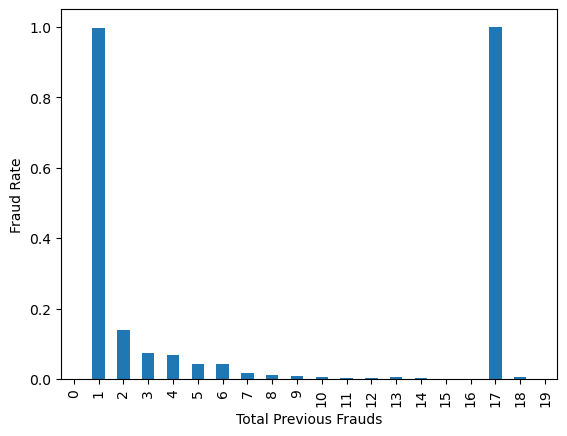

In [36]:
df_train.groupby('total_prev_fraud')['is_fraud'].mean().plot(kind = 'bar')
plt.xlabel("Total Previous Frauds")
plt.ylabel("Fraud Rate")
plt.show()

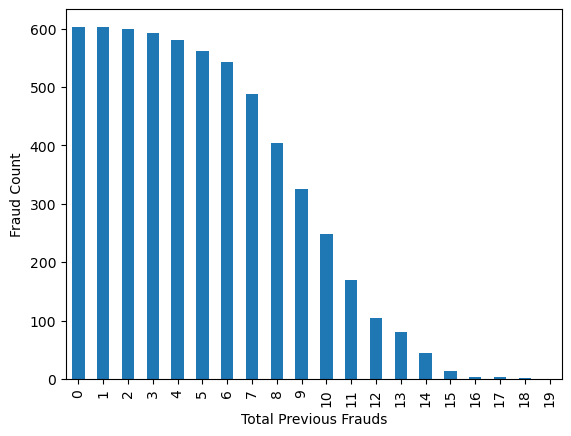

In [37]:
df_train.groupby('total_prev_fraud')['is_fraud'].sum().plot(kind = 'bar')
plt.xlabel("Total Previous Frauds")
plt.ylabel("Fraud Count")
plt.show()

In [38]:
df_train['prev_fraud_exist'] = (df_train['total_prev_fraud'] > 0).astype(int)


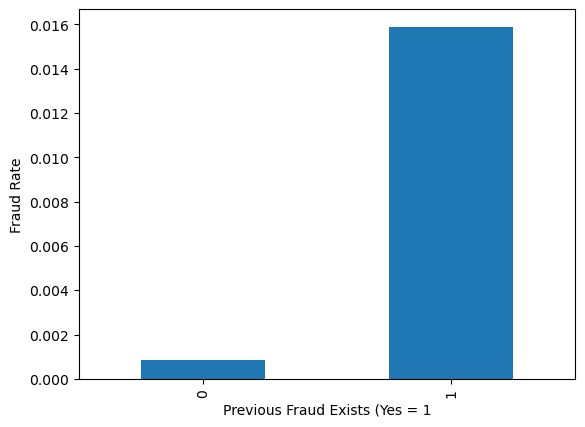

In [40]:
df_train.groupby('prev_fraud_exist')['is_fraud'].mean().plot(kind = 'bar')
plt.xlabel("Previous Fraud Exists (Yes = 1")
plt.ylabel("Fraud Rate")
plt.show()

### Summarising candidate rules:

In [129]:
rule1 = (
    ((df_train['lat'] > 60) & df_train['long'].between(-160, -145)) |
    ((df_train['merch_lat'] > 60) & df_train['merch_long'].between(-160, -145))
)

rule2 = (
    (df_train['amt'] >= 200) &
    (df_train['category'].isin(['shopping_net', 'misc_net', 'grocery_pos']))
)

rule3 = (
    (df_train['time_since_last_transaction'] <= pd.Timedelta(minutes=30)) &
    (df_train['amt'] >= 200)
)

rule4 = (
    (df_train['is_first_transaction'] == 1) &
    (df_train['amt'] >= 200)
)

rule5 = df_train['transactions_prev_60min'] >= 4

rule6 = (
    (df_train['is_first_transaction'] == 1) &
    (df_train['hour_of_day'] == 0)
)

rule7 = (
    (df_train['transactions_prev_60min'] >= 3) &
    (df_train['hour_of_day'] == 23)
)

rule8 = (df_train['prev_fraud_exist'] == 1)

In [130]:

rules = {
    "R1: suspicious location": rule1,
    "R2: amount >= 200 + risky category": rule2,
    "R3: amount >= 200 + <=30min gap": rule3,
    "R4: first transaction + amount >= 200": rule4,
    "R5: >=4 transactions in 60min": rule5,
    "R6: first transaction at 00:00": rule6,
    "R7: >=3 transactions in 60min at 23:00": rule7,
    "R8: previous fraud exists" : rule8,
    "R2 AND R7": rule2 & rule7,
    "R2 AND R8": rule2 & rule8,
    "R3 AND R7": rule3 & rule7,
    "R2 AND R5": rule2 & rule5,
    "R3 AND R5": rule3 & rule5,
    "R5 AND R7": rule5 & rule7,
    "R2 AND R3": rule2 & rule3,
    "R2 OR R3": rule2 | rule3,
    "R2 OR R3 OR R7": rule2 | rule3 | rule7,
    "R2 OR R3 OR R5 OR R7": rule2 | rule3 | rule5 | rule7,
    "R2 OR R3 OR R4 OR R5 OR R6 OR R7 OR R8":
        rule2 | rule3 | rule4 | rule5 | rule6 | rule7 | rule8,
    "High-confidence AND rules":
    (rule2 & rule7) |
    (rule3 & rule7) |
    (rule2 & rule5) |
    (rule3 & rule5) ,
}

### Rules metrics check:

In [131]:
def evaluate_rule(rule, df):
    tp = ((rule) & (df["is_fraud"] == 1)).sum()
    fp = ((rule) & (df["is_fraud"] == 0)).sum()
    fn = ((~rule) & (df["is_fraud"] == 1)).sum()
    tn = ((~rule) & (df["is_fraud"] == 0)).sum()

    return {
        "precision": tp / (tp + fp) if tp + fp else 0,
        "recall": tp / (tp + fn) if tp + fn else 0,
        "fpr": fp / (fp + tn) if fp + tn else 0,
        "coverage": rule.mean(),
        "flagged": rule.sum(),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }

In [47]:
results = pd.DataFrame([
    {"rule": name, **evaluate_rule(rule, df_train)}
    for name, rule in rules.items()
])

results = results[
    ["rule", "precision", "recall", "fpr", "coverage", "flagged", "tp", "fp", "fn", "tn"]
].sort_values("precision", ascending=False)

results

,rule,precision,recall,fpr,coverage,flagged,tp,fp,fn,tn
8,R2 AND R7,0.992000,0.020777,9.695823e-07,0.000121,125,124,1,5844,1031371
10,R3 AND R7,0.957055,0.026139,6.787076e-06,0.000157,163,156,7,5812,1031365
11,R2 AND R5,0.928571,0.008713,3.878329e-06,0.000054,56,52,4,5916,1031368
19,High-confidence AND rules,0.904762,0.031836,1.939165e-05,0.000202,210,190,20,5778,1031352
12,R3 AND R5,0.823529,0.011729,1.454373e-05,0.000082,85,70,15,5898,1031357
13,R5 AND R7,0.660714,0.012399,3.684413e-05,0.000108,112,74,38,5894,1031334
3,R4: first transaction + amount >= 200,0.526316,0.006702,3.490496e-05,0.000073,76,40,36,5928,1031336
6,R7: >=3 transactions in 60min at 23:00,0.484914,0.037701,2.317302e-04,0.000447,464,225,239,5743,1031133
14,R2 AND R3,0.398112,0.169571,1.483461e-03,0.002450,2542,1012,1530,4956,1029842
9,R2 AND R8,0.338047,0.520777,5.900878e-03,0.008863,9194,3108,6086,2860,1025286


In [132]:
rules_high_precision = (
    (rule2 & rule7) |
    (rule3 & rule7) |
    (rule2 & rule5) |
    (rule3 & rule5)
)

rules_balanced = (
    rules_high_precision |
    (rule2 & rule3)
)

rules_high_recall = (
    rules_balanced |
    (rule2 & rule8)
)

In [133]:
amt_candidates = [150 , 200 , 220 , 250 , 280 , 300]
num_transaction_at_23 = [2 , 3 , 4 , 5]
minutes_between_transaction = [20 , 30 , 40 , 50 , 60]
num_transaction_60_min = [2 , 3 , 4 , 5]


### Creating a data-transformation function, based on the previous analysis:

In [127]:
def create_features(df):
    """ 
        Input: Data frame , transactions.

        Output: Data frame, transactions with additional past-looking features , ordered by transaction time.

    """
    
    df = df.copy()

    
    df = df.sort_values(by = ['cc_num' , 'transaction_time']).reset_index(drop=True)

    
    df['running_total_amt'] = (df.groupby('cc_num')['amt'].cumsum() - df['amt'])
    
    df['running_avg_amt'] = ((df.groupby('cc_num')['amt'].cumsum() - df['amt']) /
                         df.groupby('cc_num').cumcount()).fillna(0)
    
    df['running_total_transactions'] = df.groupby('cc_num').cumcount()
    
    df['time_since_last_transaction'] = (df.groupby('cc_num')['transaction_time'].diff())

    df['transactions_last_30d'] = (
        df.set_index('transaction_time')
                .groupby('cc_num')['amt']
                .transform(lambda x: x.rolling('30D').count() - 1)
                .reset_index(drop=True)
    ).fillna(0)

    df["amt_to_avg_ratio"] = (df["amt"] / df["running_avg_amt"].replace(0, np.nan)).fillna(1)

    
    
    df['day_of_week'] = df['transaction_time'].dt.dayofweek
    df['hour_of_day'] = df['transaction_time'].dt.hour

    
    
    df['minutes_since_last_transaction'] = (df['time_since_last_transaction'].dt.total_seconds() / 60).fillna(0)

    df['is_first_transaction'] = (df['time_since_last_transaction'].isna()).astype(int)

    
    df['total_prev_fraud'] = (df.groupby('cc_num')['is_fraud'].cumsum()- df_train['is_fraud'])
    df['prev_fraud_exist'] = (df['total_prev_fraud'] > 0).astype(int)


    df["dob"] = pd.to_datetime(df["dob"])

    df["age"] = (
        df["transaction_time"].dt.year
        - df["dob"].dt.year
        - (
            (df["transaction_time"].dt.month < df["dob"].dt.month)
            | (
                (df["transaction_time"].dt.month == df["dob"].dt.month)
                & (df["transaction_time"].dt.day < df["dob"].dt.day)
            )
        ).astype(int)
    )


    
    
    lat1 = np.radians(df["lat"])
    lon1 = np.radians(df["long"])
    lat2 = np.radians(df["merch_lat"])
    lon2 = np.radians(df["merch_long"])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    df['cust_merch_distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))


    
    
    for t in [10, 30, 60]:
        df[f"transactions_prev_{t}min"] = (
            df
            .set_index('transaction_time')
            .groupby('cc_num')['cc_num']
            .rolling(f"{t}min", closed = 'left')
            .count()
            .reset_index(drop = True)
            .fillna(0)
        )


    return df.sort_values('transaction_time').reset_index(drop = True) # returns df, ordered by transaction time

## Section 2 - Training ML models, producing fraud-probabilities:

In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler , PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV
import joblib

print("Libraries Loaded")

Libraries Loaded


In [78]:
df_train = df.iloc[:split].copy()
df_train['trans_date_trans_time'] = pd.to_datetime(df_train['trans_date_trans_time'])
df_train.rename(columns = {'trans_date_trans_time' : 'transaction_time'} , inplace = True)

print(df_train.shape)

(1037340, 23)


In [128]:
df_train = create_features(df_train)

df_val = create_features(df_val)

df_test = create_features(df_test)

In [80]:
df_train.columns

Index(['Unnamed: 0', 'transaction_time', 'cc_num', 'merchant', 'category',
       'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
       'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time',
       'merch_lat', 'merch_long', 'is_fraud', 'running_total_amt',
       'running_avg_amt', 'running_total_transactions',
       'time_since_last_transaction', 'transactions_last_30d',
       'amt_to_avg_ratio', 'day_of_week', 'hour_of_day',
       'minutes_since_last_transaction', 'is_first_transaction', 'age',
       'cust_merch_distance_km', 'transactions_prev_10min',
       'transactions_prev_30min', 'transactions_prev_60min'],
      dtype='object')

In [81]:
df_train.head()

,Unnamed: 0,transaction_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,running_total_amt,running_avg_amt,running_total_transactions,time_since_last_transaction,transactions_last_30d,amt_to_avg_ratio,day_of_week,hour_of_day,minutes_since_last_transaction,is_first_transaction,age,cust_merch_distance_km,transactions_prev_10min,transactions_prev_30min,transactions_prev_60min
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,0.0,0.0,0,NaT,0.0,1.0,1,0,0.0,1,30,78.597568,0.0,0.0,0.0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,0.0,0.0,0,NaT,0.0,1.0,1,0,0.0,1,40,30.212176,0.0,0.0,0.0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,0.0,0.0,0,NaT,0.0,1.0,1,0,0.0,1,56,108.206083,0.0,0.0,0.0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,0.0,0.0,0,NaT,0.0,1.0,1,0,0.0,1,51,95.673231,0.0,0.0,0.0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,0.0,0.0,0,NaT,0.0,1.0,1,0,0.0,1,32,77.556744,0.0,0.0,0.0


In [82]:
cols_to_drop = ['is_fraud' , 'cc_num' , 'transaction_time' , 'time_since_last_transaction' , 'first' , 'last' , 'street' , 'zip' , 'trans_num' , 'unix_time' , 'dob' , 'total_prev_fraud' , 'prev_fraud_exists' ,'Unnamed: 0']

X_train = df_train.drop(columns = cols_to_drop)
y_train = df_train['is_fraud'].copy()

X_val = df_val.drop(columns = cols_to_drop)
y_val = df_val['is_fraud'].copy()

X_test = df_test.drop(columns = cols_to_drop)
y_test = df_test['is_fraud'].copy()

In [83]:
print(X_train.shape , y_train.shape)

(1037340, 26) (1037340,)


In [84]:
X_train.columns

Index(['merchant', 'category', 'amt', 'gender', 'city', 'state', 'lat', 'long',
       'city_pop', 'job', 'merch_lat', 'merch_long', 'running_total_amt',
       'running_avg_amt', 'running_total_transactions',
       'transactions_last_30d', 'amt_to_avg_ratio', 'day_of_week',
       'hour_of_day', 'minutes_since_last_transaction', 'is_first_transaction',
       'age', 'cust_merch_distance_km', 'transactions_prev_10min',
       'transactions_prev_30min', 'transactions_prev_60min'],
      dtype='object')

In [85]:
num_cols = ['amt' , 
           'city_pop' , 
           'running_total_amt' , 
           'running_total_transactions' , 
           'running_avg_amt' , 
            'amt_to_avg_ratio' ,
           'transactions_last_30d' , 
           'minutes_since_last_transaction' , 
           'is_first_transaction' , 
           'transactions_prev_10min' , 
           'transactions_prev_30min' , 
           'transactions_prev_60min' ,
           'cust_merch_distance_km' ,
           'merch_lat' ,
           'merch_long' ,
           'lat' ,
           'long' ,
           'age'
          ] 

cat_cols = ['merchant' ,
            'category' ,
            'gender' , 
            'city' ,
            'state' ,
            'job' ,
            'day_of_week' ,
            'hour_of_day'
           ]



In [86]:
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

for col in cat_cols:
    X_train[col] = X_train[col].astype(str)
    X_val[col] = X_val[col].astype(str)
    X_test[col] = X_test[col].astype(str)


In [87]:
cat_pipeline = Pipeline([
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
    )
])

#### Creating a function for cross-validation results summary:

In [88]:
def best_cv_result(grid_search, model_name):
    """
    
    Input: A fitted grid (grid object) , model name (str).

    Output: A dictionary that contains the model's name, and the results of the best estimator configuration.
    
    """
    
    i = grid_search.best_index_

    return {
        "model": model_name,
        "estimator": grid_search.best_estimator_,
        "params": grid_search.best_params_,
        "log_loss": -grid_search.cv_results_["mean_test_log_loss"][i],
        "brier": -grid_search.cv_results_["mean_test_brier"][i],
        "pr_auc": grid_search.cv_results_["mean_test_pr_auc"][i],
        "roc_auc": grid_search.cv_results_["mean_test_roc_auc"][i],
    }

In [89]:
best_models_results = []

#### Creating calibration-check functions:

In [111]:
def calibration_check(y_true, y_pred_prob, n_bins = 10):

    
    df = pd.DataFrame({
        "y_true": y_true,
        "y_pred_prob": y_pred_prob
    })

    df['bin'] = pd.cut(
        df['y_pred_prob'],
        bins = n_bins,
        include_lowest = True
    )

    return (
        df.groupby('bin', observed=True)
        .agg(
            mean_predicted_probability = ('y_pred_prob', 'mean'),
            observed_positive_rate = ('y_true', 'mean'),
            count = ('y_true', 'size')
        )
        .reset_index()
    )

In [122]:
def calibration_check_quantiles(y_true, y_pred_prob, n_quantiles = 10):

    
    df = pd.DataFrame({
        "y_true": y_true,
        "y_pred_prob": y_pred_prob
    })

    df['quantile'] = pd.qcut(
        df['y_pred_prob'],
        q = n_quantiles, 
        duplicates = 'drop'
    )

    return (
        df.groupby('quantile', observed = True)
        .agg(
            mean_predicted_probability=('y_pred_prob', 'mean'),
            observed_positive_rate=('y_true', 'mean'),
            count=('y_true', 'size')
        )
        .reset_index()
    )

### Logistic regression model:

In [91]:
logistic_preprocessor = ColumnTransformer([
    ("num" , StandardScaler() , num_cols) ,
    ("cat" , cat_pipeline , cat_cols) ]
)


logistic_model = LogisticRegression( 
    class_weight = None ,
    max_iter = 2000 ,
    solver = 'saga' ,
    random_state = 42
)

logistic_final_pipeline = Pipeline([
    ("preprocessor" , logistic_preprocessor) ,
    ("model" , logistic_model)
]
)


In [92]:
tscv = TimeSeriesSplit(n_splits = 3)

In [93]:
logistic_param_grid = {
    "model__C": [0.1, 1, 10],
    "model__penalty": ["l2"],
    "model__class_weight": [None, "balanced"]
}

In [94]:
scoring = {
    "log_loss": "neg_log_loss",
    "brier": "neg_brier_score",
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc"
}

In [95]:
logistic_grid_search = GridSearchCV(
    estimator = logistic_final_pipeline,
    param_grid = logistic_param_grid,
    scoring = scoring,
    refit = "log_loss",
    cv = tscv,
    n_jobs = 2,
    verbose = 2,
    return_train_score = True
)

In [96]:
logistic_grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 6 candidates, totalling 18 fits


GridSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['amt',
                                                                          'city_pop',
                                                                          'running_total_amt',
                                                                          'running_total_transactions',
                                                                          'running_avg_amt',
                                                                          'amt_to_avg_ratio',
                                                                          'transactions_last_30d',
                                                                          'minutes_since_last_transaction',
                                                                          'is_fi...
                                                                          'hour_of_day'])])),
                                       ('model',
                                        LogisticRegression(max_iter=2000,
                                                           random_state=42,
                                                           solver='saga'))]),
             n_jobs=2,
             param_grid={'model__C': [0.1, 1, 10],
                         'model__class_weight': [None, 'balanced'],
                         'model__penalty': ['l2']},
             refit='log_loss', return_train_score=True,
             scoring={'brier': 'neg_brier_score', 'log_loss': 'neg_log_loss',
                      'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'},
             verbose=2)

In [97]:
print("Logistic Grid Search - Finished")

Logistic Grid Search - Finished


In [98]:
best_models_results.append(best_cv_result(logistic_grid_search , "Logistic Regression"))

In [99]:
joblib.dump(
    logistic_grid_search,
    "logistic_grid_search.joblib"
)

joblib.dump(
    logistic_grid_search.best_estimator_,
    "best_logistic_model.joblib"
)

['best_logistic_model.joblib']

In [100]:
print("Logistic - saved in joblib")

Logistic - saved in joblib


### XGBoost model:

In [101]:
xgb_preprocessor = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", cat_pipeline, cat_cols)
])


xgb_model = XGBClassifier(
    objective = "binary:logistic",
    eval_metric = "logloss",
    random_state = 42,
    n_jobs = 2
)


xgb_final_pipeline = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("model", xgb_model)
])

In [102]:
neg = int((y_train == 0).sum())
pos = int((y_train == 1).sum())
scale_pos_weight_ratio = neg / pos

xgb_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8],
    "model__colsample_bytree": [0.8],
    "model__scale_pos_weight": [
        1,
        float(np.sqrt(scale_pos_weight_ratio)),
        float(scale_pos_weight_ratio),
    ],
}

print(
    f"scale_pos_weight candidates: 1, "
    f"{np.sqrt(scale_pos_weight_ratio):.3f} (sqrt), "
    f"{scale_pos_weight_ratio:.3f} (neg/pos)"
)

In [103]:
xgb_grid_search = GridSearchCV(
    estimator = xgb_final_pipeline,
    param_grid = xgb_param_grid,
    scoring = scoring,
    refit = "log_loss",
    cv = tscv,
    n_jobs = 2,
    verbose = 2,
    return_train_score = True
)

In [104]:
xgb_grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


GridSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         'passthrough',
                                                                         ['amt',
                                                                          'city_pop',
                                                                          'running_total_amt',
                                                                          'running_total_transactions',
                                                                          'running_avg_amt',
                                                                          'amt_to_avg_ratio',
                                                                          'transactions_last_30d',
                                                                          'minutes_since_last_transaction',
                                                                          'is_first...
                                                      num_parallel_tree=None, ...))]),
             n_jobs=2,
             param_grid={'model__colsample_bytree': [0.8],
                         'model__learning_rate': [0.05, 0.1],
                         'model__max_depth': [3, 5],
                         'model__n_estimators': [200, 400],
                         'model__subsample': [0.8]},
             refit='log_loss', return_train_score=True,
             scoring={'brier': 'neg_brier_score', 'log_loss': 'neg_log_loss',
                      'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'},
             verbose=2)

In [105]:
print("XGBoost Grid Search - Finished")

XGBoost Grid Search - Finished


In [106]:
best_models_results.append(best_cv_result(xgb_grid_search , "XGBoost"))

In [107]:
joblib.dump(
    xgb_grid_search,
    "xgb_grid_search.joblib"
)

joblib.dump(
    xgb_grid_search.best_estimator_,
    "best_xgb_model.joblib"
)

['best_xgb_model.joblib']

In [108]:
print("XGBoost - saved in joblib")

XGBoost - saved in joblib


### Checking results:

In [120]:
print("Logistic Regression - Calibration On Validation Set , By Bins")

calibration_check(
    y_val,
    logistic_grid_search.predict_proba(X_val)[:, 1]
)

Logistic Regression - Calibration On Validation Set , By Bins


,bin,mean_predicted_probability,observed_positive_rate,count
0,"(-0.002, 0.1]",0.004259,0.002764,257257
1,"(0.1, 0.2]",0.136825,0.140206,970
2,"(0.2, 0.3]",0.245985,0.293893,262
3,"(0.3, 0.4]",0.345699,0.503185,157
4,"(0.4, 0.5]",0.450158,0.597826,92
5,"(0.5, 0.6]",0.545663,0.671233,73
6,"(0.6, 0.7]",0.648715,0.681818,66
7,"(0.7, 0.8]",0.746218,0.831169,77
8,"(0.8, 0.9]",0.854322,0.746988,83
9,"(0.9, 1.0]",0.976562,0.872483,298


In [121]:
print("XGBoost - Calibration On Validation Set , By Bins")


calibration_check(
    y_val,
    xgb_grid_search.predict_proba(X_val)[:, 1]
)

XGBoost - Calibration On Validation Set , By Bins


,bin,mean_predicted_probability,observed_positive_rate,count
0,"(-0.001984, 0.1]",0.001095,0.000517,257014
1,"(0.1, 0.2]",0.140217,0.115538,502
2,"(0.2, 0.3]",0.245157,0.224409,254
3,"(0.3, 0.4]",0.348157,0.315385,130
4,"(0.4, 0.5]",0.448208,0.389474,95
5,"(0.5, 0.6]",0.546915,0.526882,93
6,"(0.6, 0.7]",0.647694,0.567568,74
7,"(0.7, 0.8]",0.751007,0.758621,87
8,"(0.8, 0.9]",0.854291,0.882353,170
9,"(0.9, 1.0]",0.969212,0.987991,916


In [123]:
print("Logistic Regression - Calibration On Validation Set , By Quantiles")

calibration_check_quantiles(
    y_val,
    logistic_grid_search.predict_proba(X_val)[:, 1]
)

Logistic Regression - Calibration On Validation Set , By Quantiles


,quantile,mean_predicted_probability,observed_positive_rate,count
0,"(-0.001, 0.000173]",0.000111,0.000617,25934
1,"(0.000173, 0.000285]",0.000228,0.000193,25933
2,"(0.000285, 0.000415]",0.000347,0.000270,25934
3,"(0.000415, 0.000597]",0.000500,0.000193,25933
4,"(0.000597, 0.000882]",0.000728,0.000424,25934
5,"(0.000882, 0.00141]",0.001119,0.000810,25933
6,"(0.00141, 0.00253]",0.001898,0.001465,25933
7,"(0.00253, 0.0051]",0.003637,0.001967,25934
8,"(0.0051, 0.0121]",0.007947,0.005707,25933
9,"(0.0121, 1.0]",0.056379,0.047659,25934


In [124]:
print("XGBoost - Calibration On Validation Set , By Quantiles")


calibration_check_quantiles(
    y_val,
    xgb_grid_search.predict_proba(X_val)[:, 1]
)

XGBoost - Calibration On Validation Set , By Quantiles


,quantile,mean_predicted_probability,observed_positive_rate,count
0,"(-0.0009844, 7.52e-05]",0.000057,0.000000,25934
1,"(7.52e-05, 0.000103]",0.000089,0.000000,25933
2,"(0.000103, 0.000134]",0.000118,0.000000,25934
3,"(0.000134, 0.000171]",0.000152,0.000000,25933
4,"(0.000171, 0.000221]",0.000195,0.000000,25934
5,"(0.000221, 0.000297]",0.000256,0.000000,25933
6,"(0.000297, 0.000433]",0.000357,0.000000,25933
7,"(0.000433, 0.000744]",0.000566,0.000077,25934
8,"(0.000744, 0.0017]",0.001109,0.000154,25933
9,"(0.0017, 1.0]",0.062618,0.059073,25934


In [125]:
best_models_results_df = pd.DataFrame(best_models_results)
best_models_results_df.sort_values('pr_auc' , ascending = False)

,model,estimator,params,log_loss,brier,pr_auc,roc_auc
1,XGBoost,"(ColumnTransformer(transformers=[('num', 'pass...","{'model__colsample_bytree': 0.8, 'model__learn...",0.007171,0.001693,0.849406,0.995043
0,Logistic Regression,"(ColumnTransformer(transformers=[('num', Stand...","{'model__C': 0.1, 'model__class_weight': None,...",0.020858,0.003973,0.359546,0.914092


In [115]:
best_xgb = xgb_grid_search.best_estimator_

feature_names = best_xgb.named_steps["preprocessor"].get_feature_names_out()

importances = best_xgb.named_steps["model"].feature_importances_

xgb_feature_importance = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

xgb_feature_importance.head(20)

,feature,importance
0,num__amt,0.080667
1,cat__hour_of_day_23,0.079583
2,cat__category_grocery_pos,0.053830
3,num__amt_to_avg_ratio,0.053343
4,cat__hour_of_day_22,0.052134
5,cat__category_gas_transport,0.047964
6,cat__category_entertainment,0.043091
7,num__transactions_last_30d,0.029872
8,cat__category_grocery_net,0.023648
9,cat__category_home,0.021746


### XGBoost performed better w.r.t all metrics, and in the calibration check.

Its grid search now also tunes `scale_pos_weight` for class imbalance (`1`, `sqrt(neg/pos)`, `neg/pos`).


## Section 3 - Optimising the threshold for all strategies (Rules / ML model / Hybrid):

### Rules strategy:

In [ ]:
from itertools import product
import joblib

fp_costs = [10, 30, 50, 100]  # small FP-cost sensitivity grid

# Use the already-trained XGBoost model (no retraining / no hyperparameter changes)
best_xgb = joblib.load("best_xgb_model.joblib")

print("Libraries Loaded")
print("FP cost grid:", fp_costs)
print("Loaded existing model: best_xgb_model.joblib")


In [ ]:
def evaluate_rule_with_cost(rule, df, fp_cost=30):
    metrics = evaluate_rule(rule, df)

    total_fn_cost = df.loc[
        (~rule) & (df["is_fraud"] == 1),
        "amt"
    ].sum()

    metrics["total_cost"] = (
        metrics["fp"] * fp_cost +
        total_fn_cost
    )
    metrics["fp_cost"] = fp_cost

    return metrics


def build_rule_strategies(df, amt, minutes, tx_23, tx_60):
    rule2 = (
        (df["amt"] >= amt) &
        df["category"].isin([
            "shopping_net",
            "misc_net",
            "grocery_pos"
        ])
    )

    rule3 = (
        (df["time_since_last_transaction"] <= pd.Timedelta(minutes=minutes)) &
        (df["amt"] >= amt)
    )

    rule5 = df["transactions_prev_60min"] >= tx_60

    rule7 = (
        (df["transactions_prev_60min"] >= tx_23) &
        (df["hour_of_day"] == 23)
    )

    rule8 = df["prev_fraud_exist"] == 1

    rules_high_precision = (
        (rule2 & rule7) |
        (rule3 & rule7) |
        (rule2 & rule5) |
        (rule3 & rule5)
    )

    rules_balanced = (
        rules_high_precision |
        (rule2 & rule3)
    )

    rules_high_recall = (
        rules_balanced |
        (rule2 & rule8)
    )

    return {
        "high_precision": rules_high_precision,
        "balanced": rules_balanced,
        "high_recall": rules_high_recall,
    }


In [ ]:
rule_results = []

for amt, minutes, tx_23, tx_60 in product(
    amt_candidates,
    minutes_between_transaction,
    num_transaction_at_23,
    num_transaction_60_min
):
    strategies = build_rule_strategies(
        df_val, amt, minutes, tx_23, tx_60
    )

    for strategy_name, rule in strategies.items():
        base_metrics = evaluate_rule(rule, df_val)
        total_fn_cost = df_val.loc[
            (~rule) & (df_val["is_fraud"] == 1),
            "amt"
        ].sum()

        for fp_cost in fp_costs:
            result = dict(base_metrics)
            result.update({
                "total_cost": base_metrics["fp"] * fp_cost + total_fn_cost,
                "fp_cost": fp_cost,
                "strategy": strategy_name,
                "amt_threshold": amt,
                "minutes_threshold": minutes,
                "transactions_23_threshold": tx_23,
                "transactions_60min_threshold": tx_60,
            })
            rule_results.append(result)

print(f"Evaluated {len(rule_results)} rule configurations across FP costs")


In [ ]:
rule_results = pd.DataFrame(rule_results)

best_rules_by_fp_cost = (
    rule_results
    .sort_values("total_cost")
    .groupby("fp_cost", as_index=False)
    .first()
)

best_rules_by_fp_cost[
    [
        "fp_cost",
        "strategy",
        "amt_threshold",
        "minutes_threshold",
        "transactions_23_threshold",
        "transactions_60min_threshold",
        "total_cost",
        "precision",
        "recall",
        "tp",
        "fp",
        "fn",
    ]
]


In [ ]:
# Highlight the original $30 assumption
rule_results[rule_results["fp_cost"] == 30].sort_values(
    "total_cost", ascending=True
).head(10)


In [ ]:
rule_results[
    (rule_results["fp_cost"] == 30) &
    (rule_results["strategy"] == "high_precision")
].sort_values("total_cost", ascending=True).head(10)


In [ ]:
# Best overall rules-only config per FP cost (any strategy)
# Plus best high-recall config per FP cost for the hybrid rule branch
best_rule_masks_val = {}
best_rule_masks_test = {}
high_recall_masks_val = {}
high_recall_masks_test = {}

best_high_recall_by_fp_cost = (
    rule_results[rule_results["strategy"] == "high_recall"]
    .sort_values("total_cost")
    .groupby("fp_cost", as_index=False)
    .first()
)

for _, row in best_rules_by_fp_cost.iterrows():
    fp_cost = int(row["fp_cost"])
    params = dict(
        amt=row["amt_threshold"],
        minutes=row["minutes_threshold"],
        tx_23=row["transactions_23_threshold"],
        tx_60=row["transactions_60min_threshold"],
    )
    val_strategies = build_rule_strategies(df_val, **params)
    test_strategies = build_rule_strategies(df_test, **params)
    strategy_name = row["strategy"]
    best_rule_masks_val[fp_cost] = val_strategies[strategy_name]
    best_rule_masks_test[fp_cost] = test_strategies[strategy_name]

for _, row in best_high_recall_by_fp_cost.iterrows():
    fp_cost = int(row["fp_cost"])
    params = dict(
        amt=row["amt_threshold"],
        minutes=row["minutes_threshold"],
        tx_23=row["transactions_23_threshold"],
        tx_60=row["transactions_60min_threshold"],
    )
    high_recall_masks_val[fp_cost] = build_rule_strategies(
        df_val, **params
    )["high_recall"]
    high_recall_masks_test[fp_cost] = build_rule_strategies(
        df_test, **params
    )["high_recall"]

# Keep the $30 masks under the old names for continuity
row30 = best_high_recall_by_fp_cost.loc[
    best_high_recall_by_fp_cost["fp_cost"] == 30
].iloc[0]

rules_at_30 = build_rule_strategies(
    df_val,
    amt=row30["amt_threshold"],
    minutes=row30["minutes_threshold"],
    tx_23=row30["transactions_23_threshold"],
    tx_60=row30["transactions_60min_threshold"],
)

rules_high_precision = rules_at_30["high_precision"]
rules_high_recall = high_recall_masks_val[30]
best_rules = rules_high_recall

display(best_rules_by_fp_cost)
display(best_high_recall_by_fp_cost)


In [ ]:
print("Best rules selected per FP cost")
for _, row in best_rules_by_fp_cost.iterrows():
    print(
        f"FP=${int(row['fp_cost'])}: {row['strategy']} | "
        f"amt>={row['amt_threshold']}, minutes<={row['minutes_threshold']}, "
        f"tx23>={row['transactions_23_threshold']}, "
        f"tx60>={row['transactions_60min_threshold']} | "
        f"val_cost={row['total_cost']:.2f}"
    )


## Final Rule-Strategy Selection

Rules were re-optimized on the validation set for each false-positive cost in `[10, 20, 30, 50, 100]`.

For each FP cost, the lowest-cost rule configuration (strategy + thresholds) was frozen and carried into the hybrid / test evaluation for that same cost.

The original **$30** case remains the highlighted baseline in the narrative tables below.


## Optimising thresholds of ML models:

In [ ]:
def evaluate_model_threshold(y_true, probabilities, amounts, threshold, fp_cost=30):
    predictions = probabilities >= threshold

    tp = ((predictions == 1) & (y_true == 1)).sum()
    fp = ((predictions == 1) & (y_true == 0)).sum()
    fn = ((predictions == 0) & (y_true == 1)).sum()
    tn = ((predictions == 0) & (y_true == 0)).sum()

    fn_cost = amounts[
        (predictions == 0) & (y_true == 1)
    ].sum()

    total_cost = fp * fp_cost + fn_cost

    return {
        "threshold": threshold,
        "fp_cost": fp_cost,
        "total_cost": total_cost,
        "precision": tp / (tp + fp) if tp + fp else 0,
        "recall": tp / (tp + fn) if tp + fn else 0,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }


In [ ]:
# Coarser threshold grid to keep memory/runtime low
thresholds = np.linspace(0.001, 0.40, 80)

xgb_val_prob = best_xgb.predict_proba(X_val)[:, 1]
val_amounts = df_val["amt"].to_numpy()

xgb_threshold_results = []

for fp_cost in fp_costs:
    for threshold in thresholds:
        xgb_threshold_results.append(
            evaluate_model_threshold(
                y_true=y_val,
                probabilities=xgb_val_prob,
                amounts=val_amounts,
                threshold=threshold,
                fp_cost=fp_cost,
            )
        )

xgb_threshold_results_df = pd.DataFrame(xgb_threshold_results)

best_xgb_threshold_by_fp = (
    xgb_threshold_results_df
    .sort_values("total_cost")
    .groupby("fp_cost", as_index=False)
    .first()
)

# Preserve old single-object name for the $30 baseline
best_xgb_threshold = best_xgb_threshold_by_fp.loc[
    best_xgb_threshold_by_fp["fp_cost"] == 30
].iloc[0]

best_xgb_threshold_by_fp


In [ ]:
# Logistic is not the final model; keep a light $30 threshold check only
logistic_threshold_results = []
logistic_val_prob = logistic_grid_search.best_estimator_.predict_proba(X_val)[:, 1]

for threshold in thresholds:
    logistic_threshold_results.append(
        evaluate_model_threshold(
            y_true=y_val,
            probabilities=logistic_val_prob,
            amounts=val_amounts,
            threshold=threshold,
            fp_cost=30,
        )
    )

logistic_threshold_results_df = pd.DataFrame(logistic_threshold_results)
best_logistic_threshold = logistic_threshold_results_df.loc[
    logistic_threshold_results_df["total_cost"].idxmin()
]
best_logistic_threshold


In [ ]:
best_xgb_threshold_value = float(best_xgb_threshold["threshold"])
best_xgb_threshold_value


## Machine-Learning Model Selection

Decision thresholds for both machine-learning models were re-optimized on the validation set for each false-positive cost in `[10, 20, 30, 50, 100]`. The **$30** case below remains the highlighted baseline.

### Logistic Regression

The cost-minimizing Logistic Regression threshold was **0.081**.

At this threshold, the model achieved:

- **Total cost:** $274,380.30
- **Precision:** 32.53%
- **Recall:** 56.18%
- **True positives:** 864
- **False positives:** 1,792
- **False negatives:** 674
- **True negatives:** 256,005

### XGBoost

The cost-minimizing XGBoost threshold was **0.108**.

At this threshold, the model achieved:

- **Total cost:** $61,649.07
- **Precision:** 62.15%
- **Recall:** 91.29%
- **True positives:** 1,404
- **False positives:** 855
- **False negatives:** 134
- **True negatives:** 256,942

### Final Model Selection

XGBoost substantially outperformed Logistic Regression. It achieved a much lower total cost, higher precision, higher recall, fewer false positives, and far fewer missed fraud cases.

Therefore, **XGBoost was selected as the final machine-learning model**, using a probability threshold of **0.108**.

### Optimising thresholds of  Hybrid strategies:

In [ ]:
def evaluate_predictions(y_true, predictions, amounts, fp_cost=30):
    tp = ((predictions == 1) & (y_true == 1)).sum()
    fp = ((predictions == 1) & (y_true == 0)).sum()
    fn = ((predictions == 0) & (y_true == 1)).sum()
    tn = ((predictions == 0) & (y_true == 0)).sum()

    missed_fraud_cost = amounts[
        (predictions == 0) & (y_true == 1)
    ].sum()

    return {
        "fp_cost": fp_cost,
        "total_cost": fp * fp_cost + missed_fraud_cost,
        "precision": tp / (tp + fp) if tp + fp else 0,
        "recall": tp / (tp + fn) if tp + fn else 0,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }


In [ ]:
# Hybrid 1: model OR high-precision rules (shown for $30 continuity)
hybrid_1_results = []

for threshold in thresholds:
    hybrid_predictions = (
        (xgb_val_prob >= threshold) |
        rules_high_precision
    )

    result = evaluate_predictions(
        y_true=y_val,
        predictions=hybrid_predictions,
        amounts=df_val["amt"],
        fp_cost=30,
    )
    result["threshold"] = threshold
    hybrid_1_results.append(result)

hybrid_1_results_df = pd.DataFrame(hybrid_1_results)
best_hybrid_1 = hybrid_1_results_df.loc[
    hybrid_1_results_df["total_cost"].idxmin()
]
best_hybrid_1


In [ ]:
# Hybrid 2: fixed high threshold from $30 XGB optimum + rule-supported low threshold
hybrid_2_results = []
high_threshold = float(best_xgb_threshold_value)

for low_threshold in thresholds:
    if low_threshold >= high_threshold:
        continue

    hybrid_predictions = (
        (xgb_val_prob >= high_threshold) |
        (
            (xgb_val_prob >= low_threshold) &
            rules_high_recall
        )
    )

    result = evaluate_predictions(
        y_true=y_val,
        predictions=hybrid_predictions,
        amounts=df_val["amt"],
        fp_cost=30,
    )
    result["high_threshold"] = high_threshold
    result["low_threshold"] = low_threshold
    hybrid_2_results.append(result)

hybrid_2_results_df = pd.DataFrame(hybrid_2_results)
best_hybrid_2 = hybrid_2_results_df.loc[
    hybrid_2_results_df["total_cost"].idxmin()
]
best_hybrid_2


In [ ]:
# Hybrid 3: re-optimize high/low thresholds for each FP cost (coarse grid)
high_thresholds = np.linspace(0.02, 0.30, 40)
low_thresholds = np.linspace(0.001, 0.10, 30)

hybrid_3_results = []

for fp_cost in fp_costs:
    rules_mask = high_recall_masks_val[fp_cost]

    for high_threshold in high_thresholds:
        for low_threshold in low_thresholds:
            if low_threshold >= high_threshold:
                continue

            hybrid_predictions = (
                (xgb_val_prob >= high_threshold)
                | ((xgb_val_prob >= low_threshold) & rules_mask)
            )

            result = evaluate_predictions(
                y_true=y_val,
                predictions=hybrid_predictions,
                amounts=df_val["amt"],
                fp_cost=fp_cost,
            )
            result["high_threshold"] = high_threshold
            result["low_threshold"] = low_threshold
            hybrid_3_results.append(result)

hybrid_3_results_df = pd.DataFrame(hybrid_3_results)

best_hybrid_3_by_fp = (
    hybrid_3_results_df
    .sort_values("total_cost")
    .groupby("fp_cost", as_index=False)
    .first()
)

best_hybrid_3 = best_hybrid_3_by_fp.loc[
    best_hybrid_3_by_fp["fp_cost"] == 30
].iloc[0]

best_hybrid_3_by_fp


In [ ]:
# Validation comparison at $30 (original narrative)
hybrid_comparison_df = pd.DataFrame([
    {
        "strategy": "XGBoost only",
        **best_xgb_threshold.to_dict(),
    },
    {
        "strategy": "Hybrid 1: Model OR high-precision rules",
        **best_hybrid_1.to_dict(),
    },
    {
        "strategy": "Hybrid 2: Fixed high threshold + rule-supported low threshold",
        **best_hybrid_2.to_dict(),
    },
    {
        "strategy": "Hybrid 3: Optimized high and low thresholds",
        **best_hybrid_3.to_dict(),
    },
])


In [ ]:
hybrid_comparison_df = hybrid_comparison_df.sort_values(
    "total_cost"
).reset_index(drop=True)

hybrid_comparison_df


In [ ]:
# Validation summary across all FP costs: rules vs XGB vs Hybrid 3
val_strategy_rows = []

for fp_cost in fp_costs:
    rules_row = best_rules_by_fp_cost.loc[
        best_rules_by_fp_cost["fp_cost"] == fp_cost
    ].iloc[0]
    xgb_row = best_xgb_threshold_by_fp.loc[
        best_xgb_threshold_by_fp["fp_cost"] == fp_cost
    ].iloc[0]
    hybrid_row = best_hybrid_3_by_fp.loc[
        best_hybrid_3_by_fp["fp_cost"] == fp_cost
    ].iloc[0]

    val_strategy_rows.extend([
        {
            "fp_cost": fp_cost,
            "strategy": "Rules only",
            "total_cost": rules_row["total_cost"],
            "precision": rules_row["precision"],
            "recall": rules_row["recall"],
            "threshold": np.nan,
            "high_threshold": np.nan,
            "low_threshold": np.nan,
        },
        {
            "fp_cost": fp_cost,
            "strategy": "XGBoost only",
            "total_cost": xgb_row["total_cost"],
            "precision": xgb_row["precision"],
            "recall": xgb_row["recall"],
            "threshold": xgb_row["threshold"],
            "high_threshold": np.nan,
            "low_threshold": np.nan,
        },
        {
            "fp_cost": fp_cost,
            "strategy": "Hybrid",
            "total_cost": hybrid_row["total_cost"],
            "precision": hybrid_row["precision"],
            "recall": hybrid_row["recall"],
            "threshold": np.nan,
            "high_threshold": hybrid_row["high_threshold"],
            "low_threshold": hybrid_row["low_threshold"],
        },
    ])

val_strategy_comparison_df = pd.DataFrame(val_strategy_rows)
val_strategy_comparison_df


## Hybrid Strategy Selection

Hybrid thresholds were re-optimized on the validation set for each false-positive cost in `[10, 20, 30, 50, 100]`.

For each FP cost, Hybrid 3 searches a high XGBoost threshold and a lower rule-supported threshold using the high-recall rule family selected for that cost.

The **$30** baseline comparison against XGBoost-only / Hybrid 1 / Hybrid 2 is retained above for continuity. The multi-cost validation and test summaries are produced by the following code cells.


## Section 4 - Testing frozen stategies on the Test set:

In [ ]:
xgb_test_prob = best_xgb.predict_proba(X_test)[:, 1]


In [ ]:
# Test-set rule masks are already built above; keep explicit $30 aliases
row30 = best_high_recall_by_fp_cost.loc[
    best_high_recall_by_fp_cost["fp_cost"] == 30
].iloc[0]

test_strategies_30 = build_rule_strategies(
    df_test,
    amt=row30["amt_threshold"],
    minutes=row30["minutes_threshold"],
    tx_23=row30["transactions_23_threshold"],
    tx_60=row30["transactions_60min_threshold"],
)

rules_high_precision_test = test_strategies_30["high_precision"]
rules_high_recall_test = high_recall_masks_test[30]
rules_only_test_predictions = best_rule_masks_test[30]


In [ ]:
# Frozen strategies are selected on validation for each FP cost, then scored once on test
test_results_by_fp = []

for fp_cost in fp_costs:
    rules_test_pred = best_rule_masks_test[fp_cost]

    xgb_thr = float(
        best_xgb_threshold_by_fp.loc[
            best_xgb_threshold_by_fp["fp_cost"] == fp_cost, "threshold"
        ].iloc[0]
    )
    xgb_test_pred = xgb_test_prob >= xgb_thr

    hybrid_row = best_hybrid_3_by_fp.loc[
        best_hybrid_3_by_fp["fp_cost"] == fp_cost
    ].iloc[0]
    high_thr = float(hybrid_row["high_threshold"])
    low_thr = float(hybrid_row["low_threshold"])
    hybrid_test_pred = (
        (xgb_test_prob >= high_thr) |
        (
            (xgb_test_prob >= low_thr) &
            high_recall_masks_test[fp_cost].to_numpy()
        )
    )

    rules_res = evaluate_predictions(
        y_true=y_test,
        predictions=rules_test_pred,
        amounts=df_test["amt"],
        fp_cost=fp_cost,
    )
    rules_res.update({"strategy": "Rules only", "fp_cost": fp_cost})

    xgb_res = evaluate_predictions(
        y_true=y_test,
        predictions=xgb_test_pred,
        amounts=df_test["amt"],
        fp_cost=fp_cost,
    )
    xgb_res.update({
        "strategy": "XGBoost only",
        "fp_cost": fp_cost,
        "threshold": xgb_thr,
    })

    hybrid_res = evaluate_predictions(
        y_true=y_test,
        predictions=hybrid_test_pred,
        amounts=df_test["amt"],
        fp_cost=fp_cost,
    )
    hybrid_res.update({
        "strategy": "Hybrid",
        "fp_cost": fp_cost,
        "high_threshold": high_thr,
        "low_threshold": low_thr,
    })

    test_results_by_fp.extend([rules_res, xgb_res, hybrid_res])

test_comparison_by_fp_df = pd.DataFrame(test_results_by_fp)
test_comparison_by_fp_df


In [ ]:
# $30 baseline objects preserved for the original single-cost narrative
xgb_test_predictions = (
    xgb_test_prob >= float(
        best_xgb_threshold_by_fp.loc[
            best_xgb_threshold_by_fp["fp_cost"] == 30, "threshold"
        ].iloc[0]
    )
)

hybrid_best_predictions = (
    (xgb_test_prob >= float(best_hybrid_3["high_threshold"])) |
    (
        (xgb_test_prob >= float(best_hybrid_3["low_threshold"])) &
        rules_high_recall_test.to_numpy()
    )
)


In [ ]:
rules_test_result = evaluate_predictions(
    y_true=y_test,
    predictions=rules_only_test_predictions,
    amounts=df_test["amt"],
    fp_cost=30,
)

xgb_test_result = evaluate_predictions(
    y_true=y_test,
    predictions=xgb_test_predictions,
    amounts=df_test["amt"],
    fp_cost=30,
)

hybrid_test_result = evaluate_predictions(
    y_true=y_test,
    predictions=hybrid_best_predictions,
    amounts=df_test["amt"],
    fp_cost=30,
)


In [ ]:
rules_test_result["strategy"] = "Rules only"

xgb_test_result["strategy"] = "XGBoost only"
xgb_test_result["threshold"] = float(
    best_xgb_threshold_by_fp.loc[
        best_xgb_threshold_by_fp["fp_cost"] == 30, "threshold"
    ].iloc[0]
)

hybrid_test_result["strategy"] = "Hybrid"
hybrid_test_result["high_threshold"] = float(best_hybrid_3["high_threshold"])
hybrid_test_result["low_threshold"] = float(best_hybrid_3["low_threshold"])


In [ ]:
# Saved FP-cost sensitivity results (from existing trained XGBoost; no retrain)
fp_cost_sensitivity_df = pd.read_csv("artifacts/fp_cost_sensitivity.csv")
test_comparison_by_fp_df = pd.read_csv("artifacts/test_results_by_fp_cost.csv")

mean_pct_reduction = fp_cost_sensitivity_df["hybrid_vs_xgb_pct_reduction"].mean()
median_pct_reduction = fp_cost_sensitivity_df["hybrid_vs_xgb_pct_reduction"].median()
min_pct_reduction = fp_cost_sensitivity_df["hybrid_vs_xgb_pct_reduction"].min()
max_pct_reduction = fp_cost_sensitivity_df["hybrid_vs_xgb_pct_reduction"].max()
std_pct_reduction = fp_cost_sensitivity_df["hybrid_vs_xgb_pct_reduction"].std(ddof=0)
hybrid_wins = (fp_cost_sensitivity_df["winner"] == "Hybrid").sum()

print("Test-set cost sensitivity across FP costs:")
display(fp_cost_sensitivity_df)

print("Detailed test metrics by FP cost and strategy:")
display(test_comparison_by_fp_df)

print(
    f"Mean hybrid vs XGBoost cost reduction: {mean_pct_reduction:.2f}%\n"
    f"Median: {median_pct_reduction:.2f}% | Min: {min_pct_reduction:.2f}% | "
    f"Max: {max_pct_reduction:.2f}% | Std: {std_pct_reduction:.2f}%\n"
    f"Hybrid wins: {hybrid_wins} / {len(fp_cost_sensitivity_df)} FP costs"
)

# $30 baseline slice
test_comparison_df = (
    test_comparison_by_fp_df[test_comparison_by_fp_df["fp_cost"] == 30]
    .sort_values("total_cost")
    .reset_index(drop=True)
)
print("\n$30 baseline comparison:")
display(test_comparison_df)


## Final Test-Set Results

False-positive costs evaluated: **$10, $30, $50, $100**.

For each FP cost, rules and thresholds were re-selected on validation using the **existing trained XGBoost model** (no retraining), then scored once on the untouched test set.

### Cost sensitivity table (test set)

| FP cost | Hybrid | XGBoost only | Rules only | Hybrid savings vs XGB | Hybrid % reduction vs XGB | Winner |
|---:|---:|---:|---:|---:|---:|:---|
| $10 | $55,340.66 | $71,868.99 | $290,833.77 | $16,528.33 | 23.00% | Hybrid |
| $30 | $98,710.15 | $118,626.92 | $322,673.77 | $19,916.77 | 16.79% | Hybrid |
| $50 | $119,069.12 | $147,646.92 | $354,513.77 | $28,577.80 | 19.36% | Hybrid |
| $100 | $159,015.32 | $189,345.26 | $415,002.15 | $30,329.94 | 16.02% | Hybrid |

### Distribution of hybrid improvement vs XGBoost

- **Mean % cost reduction:** 18.79%
- **Median:** 18.07%
- **Min:** 16.02%
- **Max:** 23.00%
- **Std. dev.:** 2.73%
- **Hybrid wins:** 4 / 4 FP costs

### Detailed test metrics

| FP cost | Strategy | Total cost | Precision | Recall | TP | FP | FN | Thresholds |
|---:|:---|---:|---:|---:|---:|---:|---:|:---|
| $10 | Rules only | $290,833.77 | 42.82% | 55.57% | 1,192 | 1,592 | 953 | rules config |
| $10 | XGBoost only | $71,868.99 | 42.48% | 89.56% | 1,921 | 2,601 | 224 | thr=0.052 |
| $10 | Hybrid | $55,340.66 | 41.38% | 90.21% | 1,935 | 2,741 | 210 | high=0.056, low=0.015 |
| $30 | Rules only | $322,673.77 | 42.82% | 55.57% | 1,192 | 1,592 | 953 | rules config |
| $30 | XGBoost only | $118,626.92 | 55.80% | 85.41% | 1,832 | 1,451 | 313 | thr=0.107 |
| $30 | Hybrid | $98,710.15 | 52.81% | 86.20% | 1,849 | 1,652 | 296 | high=0.128, low=0.015 |
| $50 | Rules only | $354,513.77 | 42.82% | 55.57% | 1,192 | 1,592 | 953 | rules config |
| $50 | XGBoost only | $147,646.92 | 55.80% | 85.41% | 1,832 | 1,451 | 313 | thr=0.107 |
| $50 | Hybrid | $119,069.12 | 61.87% | 82.98% | 1,780 | 1,097 | 365 | high=0.243, low=0.015 |
| $100 | Rules only | $415,002.15 | 47.24% | 55.01% | 1,180 | 1,318 | 965 | rules config |
| $100 | XGBoost only | $189,345.26 | 74.47% | 79.30% | 1,701 | 583 | 444 | thr=0.259 |
| $100 | Hybrid | $159,015.32 | 69.85% | 81.86% | 1,756 | 758 | 389 | high=0.257, low=0.042 |

### $30 baseline highlight

| Strategy | Total Cost | Precision | Recall |
|:---|---:|---:|---:|
| Hybrid | $98,710.15 | 52.81% | 86.20% |
| XGBoost only | $118,626.92 | 55.80% | 85.41% |
| Rules only | $322,673.77 | 42.82% | 55.57% |


## Project Summary

This project developed and compared three fraud-detection approaches:

1. **Rules-only detection**
2. **Machine-learning detection**
3. **A hybrid rules-and-machine-learning strategy**

The data was split chronologically into training, validation, and test sets. Exploratory data analysis supported candidate rules. XGBoost was the selected machine-learning model.

Because of compute/memory constraints, the XGBoost model was **not retrained** for this sensitivity update. The existing saved model (`best_xgb_model.joblib`) was reused.

Thresholds and rule configurations were re-optimized on the validation set under a cost-sensitive objective for a **small FP-cost grid**:

- false-positive costs: **$10, $30, $50, $100**
- false-negative cost = missed fraudulent transaction amount

For each FP cost, the chosen rules / model threshold / hybrid thresholds were frozen and evaluated once on the untouched test set.

## Final Test Performance (sensitivity)

| FP cost | Hybrid | XGBoost only | Rules only | Hybrid savings vs XGB | Hybrid % reduction vs XGB | Winner |
|---:|---:|---:|---:|---:|---:|:---|
| $10 | $55,340.66 | $71,868.99 | $290,833.77 | $16,528.33 | 23.00% | Hybrid |
| $30 | $98,710.15 | $118,626.92 | $322,673.77 | $19,916.77 | 16.79% | Hybrid |
| $50 | $119,069.12 | $147,646.92 | $354,513.77 | $28,577.80 | 19.36% | Hybrid |
| $100 | $159,015.32 | $189,345.26 | $415,002.15 | $30,329.94 | 16.02% | Hybrid |

Across this grid, the hybrid strategy reduced test cost versus XGBoost by:

- **mean 18.79%**
- median 18.07%
- range 16.02% to 23.00%
- std. dev. 2.73%

Hybrid was the lowest-cost strategy for **all 4** FP costs.

At the original **$30** baseline, hybrid test cost was **$98,710.15** versus **$118,626.92** for XGBoost-only (about **16.8%** lower).

## Final Conclusion

The hybrid strategy remains preferred: it beats XGBoost-only on every FP cost in the grid, with a mean test-set cost reduction of about **18.8%**.

## Limitations

Results still depend on the assumed false-positive cost and on using transaction amount as the cost of a missed fraudulent transaction. This analysis measures stability across a small FP-cost grid without changing the trained model.
